# Predicción con los modelos entrenados

**Proyecto final: CNNs vs Transformers para clasificación de melanoma (ISIC 2020)**

Este notebook muestra cómo usar los modelos guardados en `saved_models/` para **clasificar imágenes del conjunto de prueba**, que los modelos no vieron durante el entrenamiento ni se usaron para elegir el checkpoint, simulando cómo se usarían en una aplicación real:

1. Se cargan los tres modelos (ResNet-50, DenseNet-121 y ViT-B/16) y el **umbral de decisión** de cada uno, elegido en validación.
2. Cada imagen pasa por **el mismo preprocesamiento** que en el entrenamiento: lado corto a 256 px (notebook 00), y luego `Resize(224)` + `CenterCrop(224)` + normalización de ImageNet (notebook 02).
3. Cada modelo devuelve la **probabilidad de melanoma** y la decisión (melanoma / benigna) según su umbral.

> ⚠️ Es un ejercicio académico, **no una herramienta de diagnóstico médico**. Los modelos tienen una sensibilidad de ~35–45 % con el umbral elegido: no detectan muchos melanomas.

In [1]:
## Standard libraries
import os
import io
import zipfile
import numpy as np
import pandas as pd

## Imports for plotting
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('svg', 'pdf') # For export
import seaborn as sns
sns.set()

## PyTorch
import torch
import torch.nn as nn
## Torchvision
from torchvision import transforms, models

## Imágenes
from PIL import Image

## Utilidades del proyecto
from isic_utils import best_f1_threshold

In [ ]:
DATASET_PATH = r"C:\datasets\isic2020"
CHECKPOINT_PATH = "saved_models"
RESULTS_PATH = "results"

MODEL_NAMES = ["ResNet50", "DenseNet121", "ViT_B16"]
MODEL_LABELS = {"ResNet50": "ResNet-50", "DenseNet121": "DenseNet-121", "ViT_B16": "ViT-B/16"}
MODEL_COLORS = {"ResNet50": "#2a78d6", "DenseNet121": "#eb6834", "ViT_B16": "#1baf7a"}

device = torch.device("cuda:0") if torch.cuda.is_available() else torch.device("cpu")
print("Device:", device)

Device: cuda:0


## Cargar los modelos guardados

Reconstruimos cada arquitectura con la misma última capa (una salida) que en el notebook 02 y cargamos los pesos del mejor checkpoint. Los pesos del `ISICModule` de Lightning tienen el prefijo `model.`, que quitamos para cargarlos directamente en el modelo de `torchvision`.

In [3]:
def ResNet50(num_classes=1):
    model = models.resnet50(weights=None)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

def DenseNet121(num_classes=1):
    model = models.densenet121(weights=None)
    model.classifier = nn.Linear(model.classifier.in_features, num_classes)
    return model

def ViT_B16(num_classes=1):
    model = models.vit_b_16(weights=None)
    model.heads.head = nn.Linear(model.heads.head.in_features, num_classes)
    return model

model_dict = {"ResNet50": ResNet50, "DenseNet121": DenseNet121, "ViT_B16": ViT_B16}

def load_model(model_name):
    model = model_dict[model_name]()
    ckpt = torch.load(os.path.join(CHECKPOINT_PATH, f"{model_name}.ckpt"), map_location="cpu", weights_only=False)
    state = {k[len("model."):]: v for k, v in ckpt["state_dict"].items() if k.startswith("model.")}
    model.load_state_dict(state)
    return model.eval().to(device)

trained = {m: load_model(m) for m in MODEL_NAMES}
print("Modelos cargados:", ", ".join(MODEL_LABELS[m] for m in MODEL_NAMES))

Modelos cargados: ResNet-50, DenseNet-121, ViT-B/16


### Umbral de decisión de cada modelo

Se recalcula exactamente igual que en el notebook 03: el umbral que maximiza el F1 de melanoma **en validación**. Con `pos_weight` en la pérdida, los modelos tienden a dar probabilidades altas, por eso los umbrales son mayores a 0.5.

In [4]:
thresholds = {}
for m in MODEL_NAMES:
    val = pd.read_csv(os.path.join(RESULTS_PATH, f"preds_{m}.csv")).query("split == 'val'")
    thresholds[m], _ = best_f1_threshold(val.target, val.prob)
pd.Series({MODEL_LABELS[m]: round(t, 3) for m, t in thresholds.items()}, name="umbral").to_frame()

,umbral
ResNet-50,0.924
DenseNet-121,0.862
ViT-B/16,0.933


## Preprocesamiento y predicción

`preprocess` reproduce el pipeline completo, así que acepta imágenes de cualquier tamaño (incluidas las originales de 6000×4000 px):
1. Lado corto a 256 px con filtro Lanczos (como en el notebook 00).
2. `Resize(224)` + `CenterCrop(224)` + `ToTensor` + `Normalize` con media/std de ImageNet (el `test_transform` del notebook 02).

`predecir` procesa una lista de imágenes en un solo batch y devuelve una tabla con la probabilidad y la decisión de cada modelo.

In [5]:
IMG_SIZE = 224
DATA_MEANS = [0.485, 0.456, 0.406]
DATA_STD = [0.229, 0.224, 0.225]
test_transform = transforms.Compose([transforms.Resize(IMG_SIZE),
                                     transforms.CenterCrop(IMG_SIZE),
                                     transforms.ToTensor(),
                                     transforms.Normalize(DATA_MEANS, DATA_STD)])

def preprocess(img):
    # Acepta una ruta o una imagen PIL; replica el notebook 00 (lado corto = 256 px)
    if isinstance(img, str):
        img = Image.open(img)
    img = img.convert("RGB")
    w, h = img.size
    scale = 256 / min(w, h)
    img = img.resize((round(w * scale), round(h * scale)), Image.LANCZOS)
    return img, test_transform(img)


@torch.no_grad()
def predecir(images, names=None):
    '''
    Inputs:
        images - Lista de rutas de archivo o de imágenes PIL
        names - (opcional) Nombre para mostrar de cada imagen
    Output:
        DataFrame con la probabilidad de melanoma y la decisión de cada modelo
    '''
    if names is None:
        names = [os.path.basename(i) if isinstance(i, str) else f"imagen_{k}" for k, i in enumerate(images)]
    batch = torch.stack([preprocess(img)[1] for img in images]).to(device)
    out = pd.DataFrame({"imagen": names})
    for m in MODEL_NAMES:
        probs = torch.sigmoid(trained[m](batch)[:, 0]).cpu().numpy()
        out[f"p {MODEL_LABELS[m]}"] = probs.round(3)
        out[f"{MODEL_LABELS[m]}"] = np.where(probs >= thresholds[m], "MELANOMA", "benigna")
    votes = (out[[MODEL_LABELS[m] for m in MODEL_NAMES]] == "MELANOMA").sum(axis=1)
    out["votos melanoma"] = votes.astype(str) + "/3"
    return out

In [6]:
def mostrar_predicciones(images, names=None, true_labels=None):
    '''Muestra cada imagen junto a la probabilidad de cada modelo y su umbral.'''
    table = predecir(images, names)
    fig, axes = plt.subplots(len(images), 2, figsize=(10, 2.8 * len(images)),
                             gridspec_kw={"width_ratios": [1, 1.6]}, squeeze=False)
    for i, img in enumerate(images):
        shown = np.asarray(transforms.CenterCrop(IMG_SIZE)(transforms.Resize(IMG_SIZE)(preprocess(img)[0])))
        title = table.imagen[i]
        if true_labels is not None:
            title += f"\nReal: {'MELANOMA' if true_labels[i] == 1 else 'benigna'}"
        axes[i, 0].imshow(shown)
        axes[i, 0].set_title(title, fontsize=9)
        axes[i, 0].axis("off")

        ax = axes[i, 1]
        probs = [table.loc[i, f"p {MODEL_LABELS[m]}"] for m in MODEL_NAMES]
        y = np.arange(len(MODEL_NAMES))
        ax.barh(y, probs, color=[MODEL_COLORS[m] for m in MODEL_NAMES], height=0.55)
        for k, m in enumerate(MODEL_NAMES):
            ax.plot([thresholds[m]] * 2, [k - 0.38, k + 0.38], color="black", lw=1.5)
            ax.annotate(f"{probs[k]:.2f} → {table.loc[i, MODEL_LABELS[m]]}", (1.02, k), va="center", fontsize=9,
                        xycoords=("axes fraction", "data"))
        ax.set_yticks(y, [MODEL_LABELS[m] for m in MODEL_NAMES])
        ax.set_xlim(0, 1)
        ax.invert_yaxis()
        ax.set_xlabel("p(melanoma)  ·  línea negra = umbral del modelo", fontsize=8)
    plt.tight_layout()
    plt.show()
    return table

## Imágenes del conjunto de prueba

Tomamos al azar 3 melanomas y 3 lesiones benignas del conjunto de **prueba** (imágenes que los modelos no vieron durante el entrenamiento), para comparar la predicción con la etiqueta real.

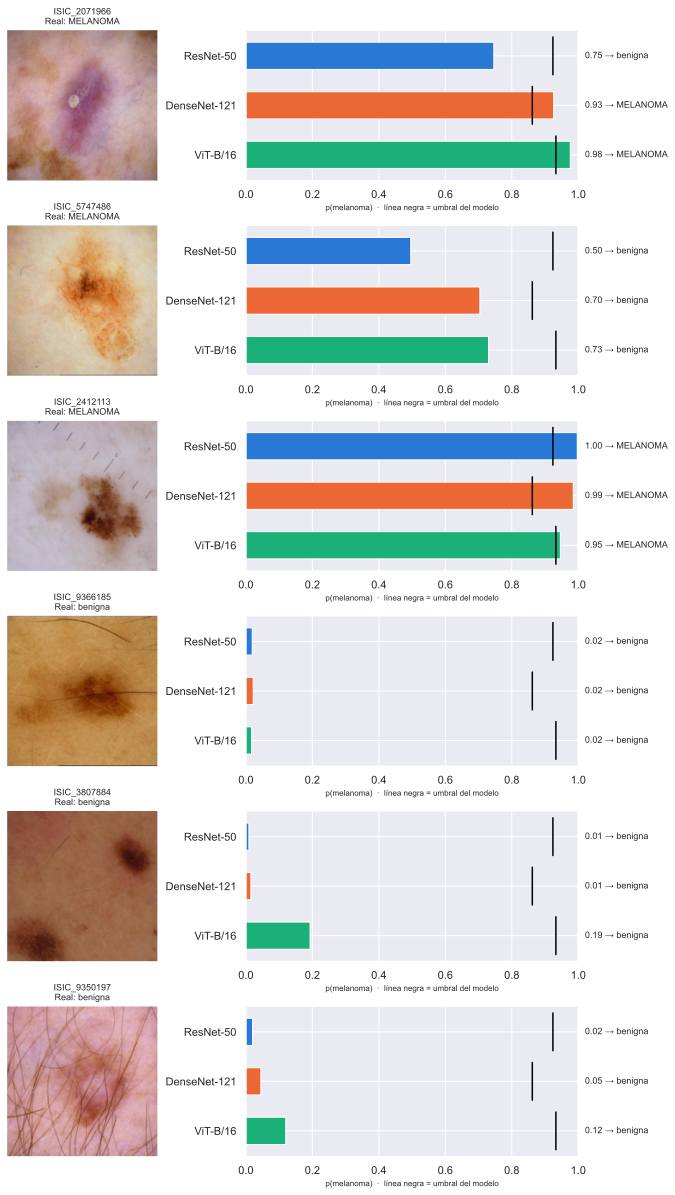

,imagen,p ResNet-50,ResNet-50,p DenseNet-121,DenseNet-121,p ViT-B/16,ViT-B/16,votos melanoma,real
0,ISIC_2071966,0.746,benigna,0.926,MELANOMA,0.976,MELANOMA,2/3,MELANOMA
1,ISIC_5747486,0.496,benigna,0.704,benigna,0.730,benigna,0/3,MELANOMA
2,ISIC_2412113,0.997,MELANOMA,0.985,MELANOMA,0.946,MELANOMA,3/3,MELANOMA
3,ISIC_9366185,0.019,benigna,0.022,benigna,0.017,benigna,0/3,benigna
4,ISIC_3807884,0.009,benigna,0.015,benigna,0.193,benigna,0/3,benigna
5,ISIC_9350197,0.020,benigna,0.045,benigna,0.120,benigna,0/3,benigna


In [7]:
split = pd.read_csv(os.path.join(DATASET_PATH, "train_256_split.csv"))
test = split[split.split == "test"]
sample = pd.concat([test[test.target == 1].sample(3, random_state=7),
                    test[test.target == 0].sample(3, random_state=7)]).reset_index(drop=True)

table = mostrar_predicciones(sample.image_path.tolist(), names=sample.image_name.tolist(), true_labels=sample.target.tolist())
table.assign(real=np.where(sample.target == 1, "MELANOMA", "benigna"))

## Imagen original a resolución completa

Para comprobar que el pipeline funciona con imágenes "crudas", leemos una imagen de prueba **directamente del zip original** de ISIC (resolución completa, sin el preprocesamiento del notebook 00). `preprocess` aplica el mismo redimensionamiento, así que la predicción debe coincidir con la de la versión de 256 px.

In [8]:
example = sample.iloc[0]
with zipfile.ZipFile(os.path.join(DATASET_PATH, "ISIC_2020_Training_JPEG.zip")) as zf:
    raw = Image.open(io.BytesIO(zf.read(f"train/{example.image_name}.jpg")))
    raw.load()
print(f"{example.image_name}: original {raw.size[0]}×{raw.size[1]} px")

comparison = pd.concat([predecir([raw], names=[f"{example.image_name} (original {raw.size[0]}×{raw.size[1]})"]),
                        predecir([example.image_path], names=[f"{example.image_name} (versión 256 px del notebook 00)"])])
comparison

ISIC_2071966: original 2592×1936 px


,imagen,p ResNet-50,ResNet-50,p DenseNet-121,DenseNet-121,p ViT-B/16,ViT-B/16,votos melanoma
0,ISIC_2071966 (original 2592×1936),0.787,benigna,0.918,MELANOMA,0.975,MELANOMA,2/3
0,ISIC_2071966 (versión 256 px del notebook 00),0.746,benigna,0.926,MELANOMA,0.976,MELANOMA,2/3
